<table align="center">
  <td align="center"><a target="_blank" href="http://introtodeeplearning.com">
        <img src="https://i.ibb.co/Jr88sn2/mit.png" style="padding-bottom:5px;" />
      Visit MIT Deep Learning</a></td>
  <td align="center"><a target="_blank" href="https://colab.research.google.com/github/MITDeepLearning/introtodeeplearning/blob/master/lab1/TF_Part2_Music_Generation.ipynb">
        <img src="https://i.ibb.co/2P3SLwK/colab.png"  style="padding-bottom:5px;" />Run in Google Colab</a></td>
  <td align="center"><a target="_blank" href="https://github.com/MITDeepLearning/introtodeeplearning/blob/master/lab1/TF_Part2_Music_Generation.ipynb">
        <img src="https://i.ibb.co/xfJbPmL/github.png"  height="70px" style="padding-bottom:5px;"  />View Source on GitHub</a></td>
</table>

# Copyright Information

In [1]:
# Copyright 2026 MIT Introduction to Deep Learning. All Rights Reserved.
#
# Licensed under the MIT License. You may not use this file except in compliance
# with the License. Use and/or modification of this code outside of MIT Introduction
# to Deep Learning must reference:
#
# © MIT Introduction to Deep Learning
# http://introtodeeplearning.com
#

In [6]:
# Import Tensorflow 2.0
import tensorflow as tf

# Download and import the MIT Introduction to Deep Learning package
!pip install mitdeeplearning --quiet
import mitdeeplearning as mdl

# Import all remaining packages
import numpy as np
import os
import time
import functools
from IPython import display as ipythondisplay
from tqdm import tqdm
from scipy.io.wavfile import write

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Train text

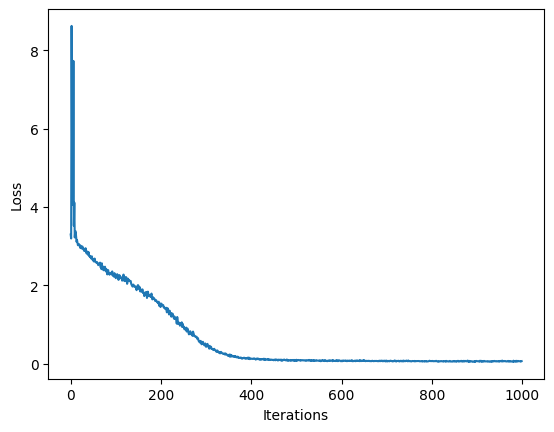

100%|██████████| 1000/1000 [29:01<00:00,  1.74s/it]


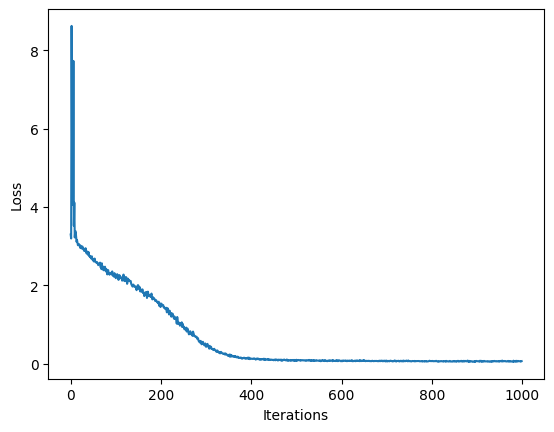

In [21]:

def get_batch(vectorized_songs, seq_length, batch_size):
   # the length of the vectorized songs string
   n = vectorized_songs.shape[0] - 1
   # randomly choose the starting indices for the examples in the training batch
   idx = np.random.choice(n-seq_length, batch_size)

   input_batch = []
   output_batch = []

   for start in idx:
      input_sequence = vectorized_songs[start : start + seq_length]
      target_sequence = vectorized_songs[start + 1 : start + seq_length + 1]

      input_batch.append(input_sequence)
      output_batch.append(target_sequence)

   # x_batch, y_batch provide the true inputs and targets for network training
   x_batch = np.reshape(input_batch, [batch_size, seq_length])
   y_batch = np.reshape(output_batch, [batch_size, seq_length])
   return x_batch, y_batch

def LSTM(rnn_units):
  return tf.keras.layers.LSTM(
    rnn_units,
    return_sequences=True,
    recurrent_initializer='glorot_uniform',
    recurrent_activation='sigmoid',
    stateful=False,
  )

### Defining the RNN Model ###

def build_model(vocab_size, embedding_dim, rnn_units, batch_size):
  model = tf.keras.Sequential([
    # Layer 1: Embedding layer to transform indices into dense vectors
    #   of a fixed embedding size
    tf.keras.layers.Embedding(vocab_size, embedding_dim),

    # Layer 2: LSTM with `rnn_units` number of units.
    LSTM(rnn_units),

    # Layer 3: Dense (fully-connected) layer that transforms the LSTM output
    #   into the vocabulary size.
    tf.keras.layers.Dense(vocab_size)
  ])

  return model

def compute_loss(labels, logits):
  loss = tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
  return loss

@tf.function
def train_step(x, y):
  # Use tf.GradientTape()
  with tf.GradientTape() as tape:

    y_hat = model_text(x)

    loss = compute_loss(y, y_hat)

  # Now, compute the gradients
  grads = tape.gradient(loss, model_text.trainable_variables)

  # Apply the gradients to the optimizer so it can update the model accordingly
  optimizer.apply_gradients(zip(grads, model_text.trainable_variables))
  return loss

# main start
training_story = """cat kot dog pies fish ryba bird ptak horse kon cow krowa pig swinia rabbit krolik mouse mysz duck kaczka chicken kurczak sheep owca goat koza
house dom room pokoj door drzwi window okno table stol chair krzeslo bed lozko lamp lampa kitchen kuchnia garden ogrod
book ksiazka pen dlugopis bag torba key klucz phone telefon computer komputer school szkola teacher nauczyciel student uczen
friend przyjaciel family rodzina mother matka father ojciec sister siostra brother brat child dziecko baby niemowle
city miasto village wies street ulica road droga park park shop sklep market rynek station stacja
tree drzewo flower kwiat grass trawa sun slonce moon ksiezyc star gwiazda sky niebo cloud chmura rain deszcz snow snieg
water woda milk mleko bread chleb apple jablko pear gruszka cheese ser soup zupa coffee kawa tea herbata cake ciasto
car samochod bus autobus train pociag bicycle rower boat lodz plane samolot road droga bridge most
ball pilka toy zabawka game gra music muzyka song piosenka picture obraz map mapa clock zegar gift prezent
word slowo name imie question pytanie answer odpowiedz idea pomysl story opowiesc language jezyk color kolor number liczba"""
text = (training_story + "\n") * 20
vocabtext = sorted(set(text))
char_to_id = {char: i for i, char in enumerate(vocabtext)}
vectorized_text = np.array([char_to_id[c] for c in text], dtype=np.int32)


print("There are", len(vectorized_text), "characters in the test dataset ")
print("There are", len(vocabtext), "unique characters in the test dataset ")

x_batch_text, y_batch_text = get_batch(vectorized_text, seq_length=5, batch_size=1)

modeltext = build_model(len(vocabtext), embedding_dim=256, rnn_units=1024, batch_size=32)
modeltext.build(tf.TensorShape([32, 100])) 
modeltext.summary()

x_text, y_text = get_batch(vectorized_text, seq_length=100, batch_size=32)
pred_text = modeltext(x_text)
print("Input shape:      ", x_text.shape, " # (batch_size, sequence_length)")
print("Prediction shape: ", pred_text.shape, "# (batch_size, sequence_length, vocab_size)")

example_batch_loss_text = compute_loss(y_text, pred_text)

print("Prediction shape: ", pred_text.shape, " # (batch_size, sequence_length, vocab_size)")
print("scalar_loss:      ", example_batch_loss_text.numpy().mean())

vocab_size_text = len(vocabtext)

# Model parameters:
params = dict(
  num_training_iterations = 1000,  # Increase if the generated text is still random
  batch_size = 8,  # Experiment between 1 and 64
  seq_length = 100,  # Experiment between 50 and 500
  learning_rate = 5e-3,  # Experiment between 1e-5 and 1e-1
  embedding_dim = 256,
  rnn_units = 1024,  # Experiment between 1 and 2048
)

# Checkpoint location:
checkpoint_dir_text = './training_checkpoints_text'
checkpoint_prefix_text = os.path.join(checkpoint_dir_text, "my_ckpt.weights.h5")
os.makedirs(checkpoint_dir_text, exist_ok=True)


### Define optimizer and training operation ###

model_text = build_model(vocab_size_text, params["embedding_dim"], params["rnn_units"], params["batch_size"])

optimizer = tf.keras.optimizers.Adam(params["learning_rate"])


##################
# Begin training!#
##################

history = []
plotter = mdl.util.PeriodicPlotter(sec=2, xlabel='Iterations', ylabel='Loss')

if hasattr(tqdm, '_instances'): tqdm._instances.clear() # clear if it exists
for iter in tqdm(range(params["num_training_iterations"])):

  # Grab a batch and propagate it through the network
  x_batch_text, y_batch_text = get_batch(vectorized_text, params["seq_length"], params["batch_size"])
  loss = train_step(x_batch_text, y_batch_text)

  history.append(loss.numpy().mean())
  plotter.plot(history)

  # Update the model with the changed weights!
  if iter % 100 == 0:
    model_text.save_weights(checkpoint_prefix_text)

# Save the trained model and the weights
model_text.save_weights(checkpoint_prefix_text)

## Testing model

In [24]:
def generate_text(model, start_string, generation_length=10):
    input_ids = [char_to_id[c] for c in start_string]
    id_to_char = {idx: char for char, idx in char_to_id.items()}
    text_generated = []

    for _ in range(generation_length):
        context = input_ids[-params["seq_length"]:]
        input_eval = tf.constant([context], dtype=tf.int32)
        predictions = model(input_eval)
        next_logits = predictions[0, -1, :]
        predicted_id = tf.random.categorical(
            next_logits[tf.newaxis, :], num_samples=1
        )[0, 0].numpy()

        input_ids.append(int(predicted_id))
        text_generated.append(id_to_char[int(predicted_id)])

    return start_string + "".join(text_generated)


start_string = "dog"
generated_text = generate_text(
    model_text, start_string=start_string, generation_length=15
)
print(generated_text)

dog pies fish ryba
